# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="curve_1_error_comparison.png" alt="Alt text" width=95%>

Simpson's rules achievse the lowest error in curve 1, it shrinks as sample points increase. The trapezoidal rule also follows the same trend. The Monte Carlo error stays consistently flat with random jumps (likely due to its reliances on randomness).

<img src="curve_1_monte_carlo_sampling.png" alt="Alt text" width=95%>

Random points are scatters in the bounding box that encloses the curve. The ratio of the points inside (blue points) and the points outside (grey points) estimate the curve's area.

<img src="curve_2_error_comparison.png" alt="Alt text" width=95%>

Simpson's 3/8 integrates polynomials to degree 3 perfectly as it drops to almost zero error. Simpson's 1/3 and Trapezoidal rules show steady error reduction while Monte Carlo remains noisy.

<img src="curve_2_monte_carlo_sampling.png" alt="Alt text" width=95%>

The points inside and above (blue) and the points inside and below (red) are subtracted from each other to obtain the net signed area.

<img src="curve_3_error_comparison.png" alt="Alt text" width=95%>

Simpson's rule shows that it performs better than the trapezoidal rule despite the sharp root. Trepezoidal error drops smoothly while the Monte Carlo error jumps randomly (as always) due to randomness.

<img src="curve_3_monte_carlo_sampling.png" alt="Alt text" width=95%>

The positive wave region points (blue) and the negative wave region points (red) visualizes how the Monte Carlo integration handles changes in sign across the zero-crossing.

### Report discussion

#### Why can we arrive at an integration value using Monte Carlo simulation?

The Monte Carlo integration estimates an integral by using random points in a bounding rectangle. It then checks whther the points that land under the curve equals the ratio of the integrated area. This essentially estimates the area by tracking points above and below the x-axis. It calculates these points seperatley to get the net signed area.

#### When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?

Neton-Cotes methods are better for simple and smooth 1D functions because they are deterministic. Meaning they have formulas that converge to exact answers fast. The main downside of the Monte Carlo is that its slow and relies on randomness making it inneficient for 1D integrals.

### Other comments
- 冰凍三尺，非一日之寒

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
def monte_carlo_integration(f, a, b , N):
    x_dense = np.linspace(a, b, 1000)
    y_dense = f(x_dense)
    y_min, y_max = min(0, np.min(y_dense)), max(0, np.max(x_dense))

    # Padding
    y_range = y_max - y_min # calculates height given a and b
    if y_range == 0: y_range = 1.0 # avoids zero values
    y_min_box = y_min - 0.05 * y_range 
    y_max_box = y_max + 0.05 * y_range # adds 5 percent more space so we dont clip anything
    
    x_pts = np.random.uniform(a, b, N) # generates random x coordinate values
    y_pts = np.random.uniform(y_min_box, y_max_box, N) # generates random y coordinate values
    
    fx_pts = f(x_pts) # evaluates the function we just made randomly

    # determining negative and positive values

    inside_positive = (y_pts >= 0) & (y_pts <= fx_pts) # finds all positive points above x axis
    inside_negative = (y_pts <= 0) & (y_pts >= fx_pts) # finds all negative points below x axis
    inside_mask = inside_positive | inside_negative # combines found negative and positive points

    box_area = (b - a) * (y_max_box - y_min_box) # after finding points, generates the box to enclose all the points

    # this gives us our signed area
    signed_fraction = (np.sum(inside_positive) - np.sum(inside_negative)) / N # adds the signed points and divides by total points givind us the weighted fraction
    signed_area = box_area * signed_fraction # gives us the signed integral

    # this gives us our total area (absolute value)
    total_fraction = np.sum(inside_mask) / N
    total_area = box_area * total_fraction # calculates total space enclosed
    
    return signed_area, total_area, (x_pts, y_pts, inside_mask)

In [3]:
def trapezoidal_integration(f, a, b, n):
    x = np.linspace(a, b, n + 1)
    y = f(x)
    dx = (b-a) / n

    # this gives us our signed area
    signed_area = (dx / 2.0) * y[0] + 2 * np.sum(y[1:-1] + y[-1])

    # total area
    y_abs = np.abs(y)
    total_area = (dx / 2.0) * y_abs[0] + 2 * np.sum(y_abs[1:-1] + y_abs[-1])

    return signed_area, total_area

In [4]:
def simpson13_integration(f, a, b, n):
    # must be even
    if n % 2 != 0: # modulo checks the remainder, only if zero we have evven
        n += 1  # adjusts it to even

    x = np.linspace(a, b , n + 1)
    y = f(x)
    dx = (b - a) / n

    # signed area
    signed_area = (dx / 3.0) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[1])

    # this gives us toal area
    y_abs = np.abs(y)
    total_area = (dx / 3.0) * (y_abs[0] + 4 * np.sum(y_abs[1:-1:2]) + 2 * np.sum(y_abs[2:-2:2]) + y_abs[1])

    return signed_area, total_area

In [5]:
def simpson38_integration(f, a, b, n):
    if n % 3 != 0: # checks if divisable by 3
        n = ((n // 3) + 1) * 3 # adjusts it to multiple of 3
    
    x = np.linspace(a, b, n + 1)
    y = f(x)
    dx = (b - a) / n

    # weight calculation
    weights = np.ones(n + 1) # makes an array of ones
    weights[1:-1] = 3 # changes all array elements to 3 except endpoints
    weights[3:-1:3] = 2 # changes every third element into 2 except first and last

    # signed area
    signed_area = (3 * dx / 8.0) * np.sum(weights * y)

    # total area
    y_abs = np.abs(y)
    total_area = (3 * dx / 8.0) * np.sum(weights * y_abs)

    return signed_area, total_area

In [6]:
# test points setup
test_case = [
    {
        "name": r"$y = \sqrt{9 - 4x^2}$",
        "function": lambda x: np.sqrt(np.maximum(0, 9 - 4 * x**2)), # np.maximum safety check against tiny floating-point negatives
        "a": 0.0, # lower limit of integration
        "b": 1.5, # upper limit of integration
    },
    {
        "name": r"$y = -x^2 + 1$",
        "function": lambda x: -x**2 + 1,
        "a": -2.0, # lower limit
        "b": 2.0,  # upper limit
    },
    {
        "name": r"$y = \sqrt{x}\cos(x)$",
        "function": lambda x: np.sqrt(np.maximum(0, x)) * np.cos(x),
        "a": 0.0,   # lower limit
        "b": np.pi, # upper limit
    }
]

In [7]:
np.random.seed(42)  # so we can reproduce values

for idx, case in enumerate(test_case, 1):
    f = case["function"]
    a, b = case["a"], case["b"]
    
    # using scipy integrate to find true values
    exact_integral, _ = quad(f, a, b)
    exact_total_area, _ = quad(lambda x: np.abs(f(x)), a, b)
    
    # computing using our defined funcitons
    N_sample = 6000
    mc_sig, mc_tot, _ = monte_carlo_integration(f, a, b, N_sample)
    trap_sig, trap_tot = trapezoidal_integration(f, a, b, N_sample)
    s13_sig, s13_tot = simpson13_integration(f, a, b, N_sample)
    s38_sig, s38_tot = simpson38_integration(f, a, b, N_sample)
    
    print("=" * 65)
    print(f"Test Curve {idx}: {case['name']}  |  Bounds: [{a:.2f}, {b:.2f}]")
    print("=" * 65)
    print(f"{'Method':<25} | {'Signed Area (Integral)':<22} | {'Total Bounded Area':<20}")
    print("-" * 65)
    print(f"{'scipy.integrate.quad':<25} | {exact_integral:<22.6f} | {exact_total_area:<20.6f}")
    print(f"{'Monte Carlo (N=' + str(N_sample) + ')':<25} | {mc_sig:<22.6f} | {mc_tot:<20.6f}")
    print(f"{'Trapezoidal':<25} | {trap_sig:<22.6f} | {trap_tot:<20.6f}")
    print(f"{'Simpsons 1/3':<25} | {s13_sig:<22.6f} | {s13_tot:<20.6f}")
    print(f"{'Simpsons 3/8':<25} | {s38_sig:<22.6f} | {s38_tot:<20.6f}\n")

Test Curve 1: $y = \sqrt{9 - 4x^2}$  |  Bounds: [0.00, 1.50]
Method                    | Signed Area (Integral) | Total Bounded Area  
-----------------------------------------------------------------
scipy.integrate.quad      | 3.534292               | 3.534292            
Monte Carlo (N=6000)      | 2.241525               | 2.241525            
Trapezoidal               | 28271.311485           | 28271.311485        
Simpsons 1/3              | 3.534541               | 3.534541            
Simpsons 3/8              | 3.534290               | 3.534290            

Test Curve 2: $y = -x^2 + 1$  |  Bounds: [-2.00, 2.00]
Method                    | Signed Area (Integral) | Total Bounded Area  
-----------------------------------------------------------------
scipy.integrate.quad      | -1.333333              | 4.000000            
Monte Carlo (N=6000)      | -1.232000              | 4.055333            
Trapezoidal               | -39988.001889          | 47988.001000        
Simpsons 1/

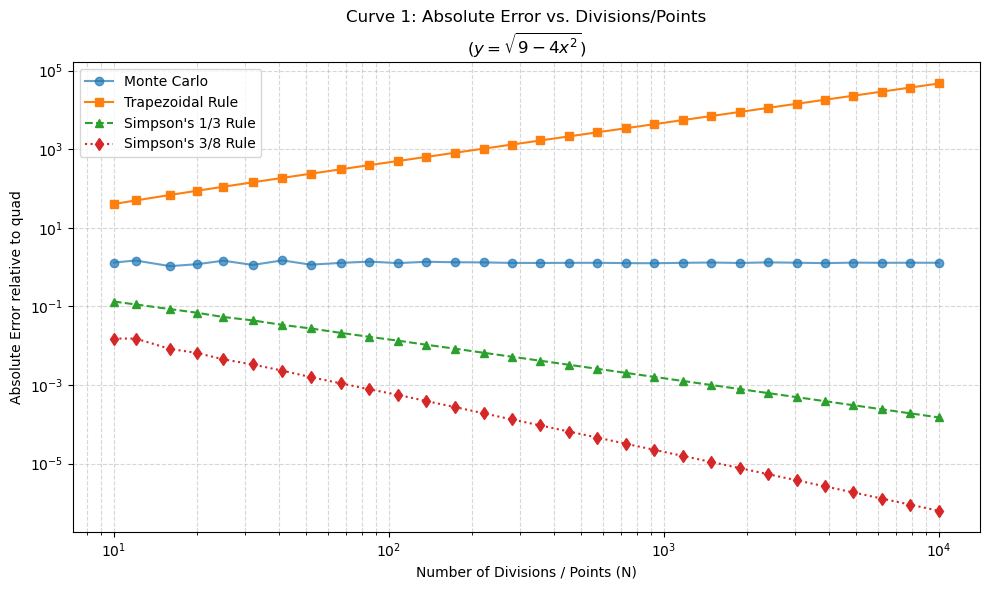

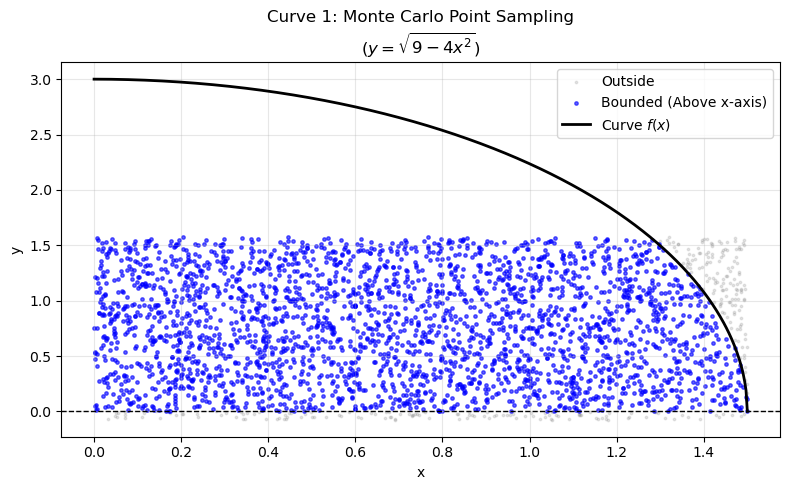

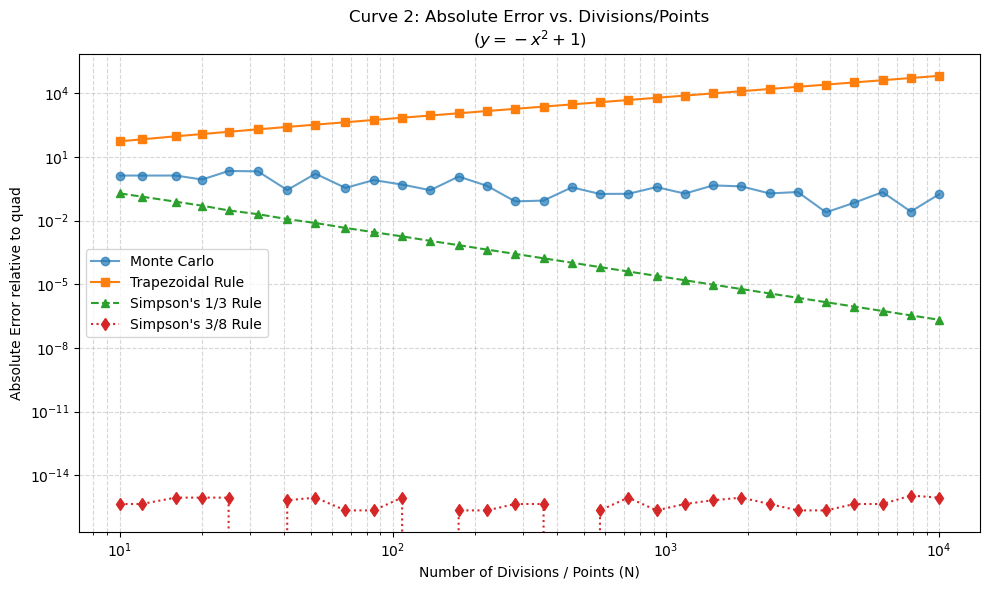

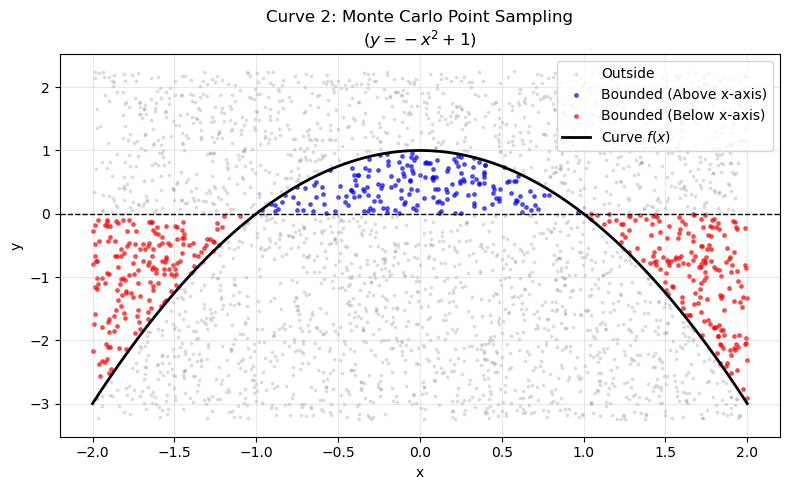

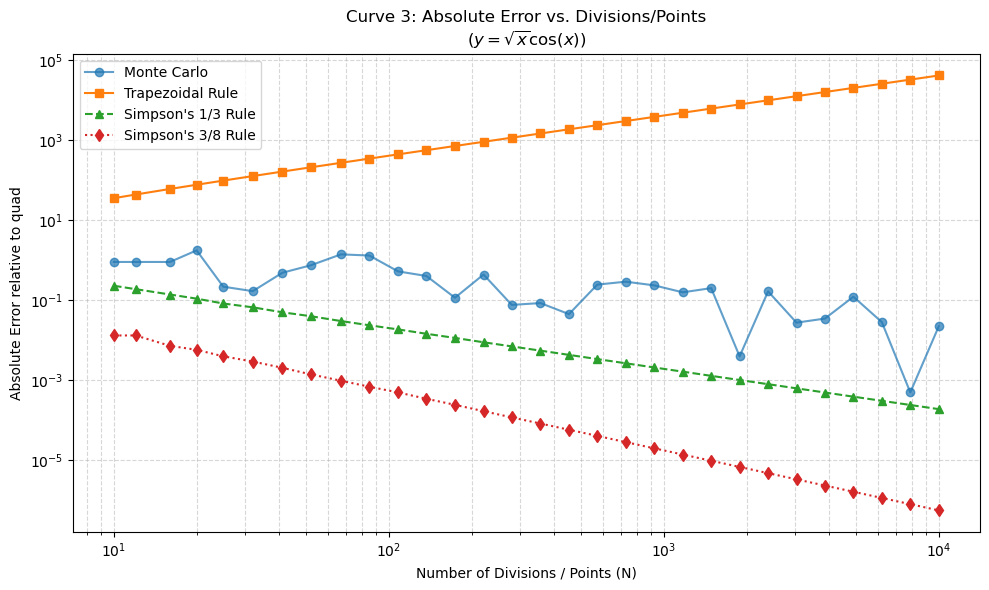

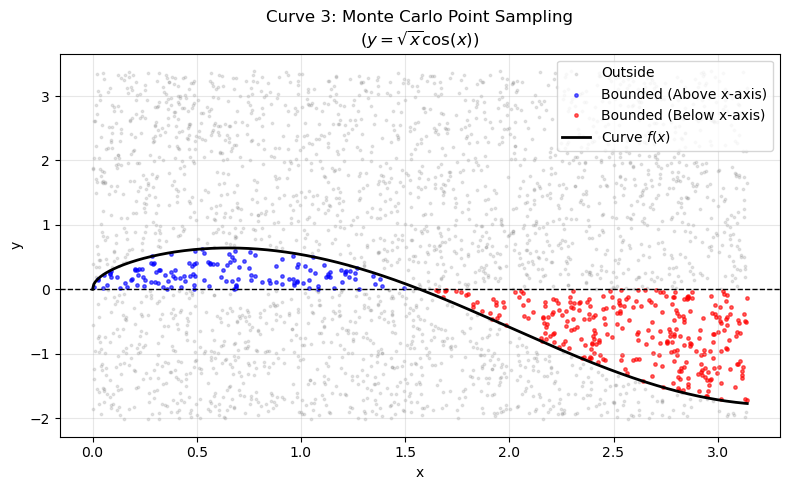

In [9]:
for idx, case in enumerate(test_case, 1):
    f = case["function"]
    a, b = case["a"], case["b"]
    exact_val, _ = quad(f, a, b)

    plt.figure(figsize=(10, 6))
    divisions = np.unique(np.logspace(1, 4, 30, dtype=int))

    err_mc, err_trap, err_s13, err_s38 = [], [], [], []
    
    for n in divisions:
        mc_val, _, _ = monte_carlo_integration(f, a, b, n)
        err_mc.append(abs(mc_val - exact_val))
    
        trap_val, _ = trapezoidal_integration(f, a, b, n)
        err_trap.append(abs(trap_val - exact_val))
    
        s13_val, _ = simpson13_integration(f, a, b, n)
        err_s13.append(abs(s13_val - exact_val))
    
        s38_val, _ = simpson38_integration(f, a, b, n)
        err_s38.append(abs(s38_val - exact_val))

    plt.loglog(divisions, err_mc, 'o-', label="Monte Carlo", alpha=0.7)
    plt.loglog(divisions, err_trap, 's-', label="Trapezoidal Rule")
    plt.loglog(divisions, err_s13, '^--', label="Simpson's 1/3 Rule")
    plt.loglog(divisions, err_s38, 'd:', label="Simpson's 3/8 Rule")

    plt.title(f"Curve {idx}: Absolute Error vs. Divisions/Points\n({case['name']})")
    plt.xlabel("Number of Divisions / Points (N)")
    plt.ylabel("Absolute Error relative to quad")
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"curve_{idx}_error_comparison.png", dpi=300, bbox_inches='tight')
    plt.show()

    plt.figure(figsize=(8, 5))
    
    N_vis = 3000
    _, _, (x_pts, y_pts, inside_mask) = monte_carlo_integration(f, a, b, N_vis)
    
    blue_mask = inside_mask & (y_pts >= 0)  
    red_mask = inside_mask & (y_pts < 0)    
    outside_mask = ~inside_mask
    
    plt.scatter(x_pts[outside_mask], y_pts[outside_mask], color='grey', s=3, alpha=0.2, label='Outside')
    if np.any(blue_mask):
        plt.scatter(x_pts[blue_mask], y_pts[blue_mask], color='blue', s=6, alpha=0.6, label='Bounded (Above x-axis)')
    if np.any(red_mask):
        plt.scatter(x_pts[red_mask], y_pts[red_mask], color='red', s=6, alpha=0.6, label='Bounded (Below x-axis)')
        
    x_curve = np.linspace(a, b, 500)
    plt.plot(x_curve, f(x_curve), 'k-', linewidth=2, label='Curve $f(x)$')
    plt.axhline(0, color='black', linestyle='--', linewidth=1)
    
    plt.title(f"Curve {idx}: Monte Carlo Point Sampling\n({case['name']})")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"curve_{idx}_monte_carlo_sampling.png", dpi=300, bbox_inches='tight')
    plt.show()